# 04 · Structure de courbe & régime

**Objectif** : structure de courbe WTI (contango/backwardation, roll yield), lien avec le spread, et détection de régime (cointégration glissante, ruptures).

In [1]:
import sys, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, "..")
%matplotlib inline
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True
from src import (data_loader as dl, features as ft, stats_tests as st,
                 hedge_ratio as hr, signal as sig, backtest as bt, metrics as mt,
                 curve as cv, regime as rg, pipeline as pl)
from src.config import StrategyConfig, MARKET_EVENTS, REGIME_SEGMENTS
def events(ax):
    for e in MARKET_EVENTS:
        ax.axvline(pd.Timestamp(e["date"]), color="gray", ls=":", lw=1, alpha=.6)

prices = dl.get_prices('futures')
curve = dl.get_curve()
print('courbe EIA :', None if curve is None else (curve.shape, str(curve.index.max().date())))

courbe EIA : ((10310, 4), '2024-04-05')


### Contango / backwardation & roll yield  (EIA RCLC1..4, ≤ 2024-04-05)

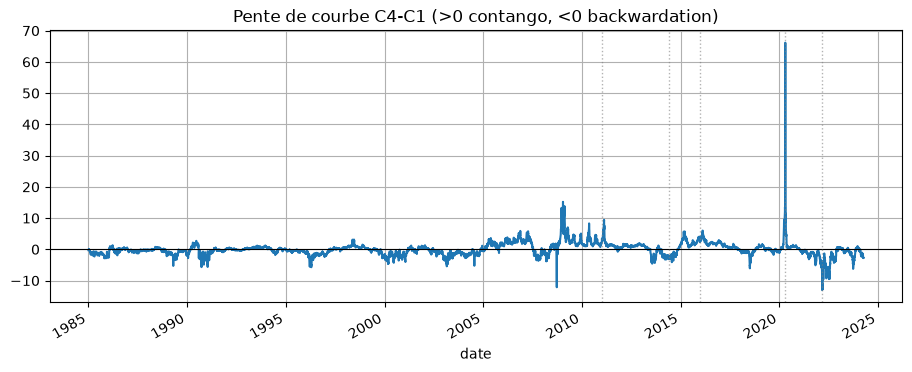

répartition régimes (%):
regime
backwardation    52.0
contango         47.8
flat              0.3
Name: proportion, dtype: float64
roll yield annualisé moyen : 0.4%


In [2]:
cf = cv.curve_features(curve)
ax = cf['slope'].plot(title='Pente de courbe C4-C1 (>0 contango, <0 backwardation)')
ax.axhline(0, color='k', lw=.8); events(ax); plt.show()
print('répartition régimes (%):'); print((cv.regime_share(cf)*100).round(1))
print('roll yield annualisé moyen : %.1f%%' % (cf['roll_yield_ann'].mean()*100))

### Lien courbe ↔ spread & rendements forward

In [3]:
link = cv.link_curve_to_spread(cf, ft.price_spread(prices))
print('corr pente/spread :', round(link['corr_slope_spread'],3))
print('spread moyen par régime de courbe:'); print(link['spread_by_regime'].round(2))
fwd = cv.curve_vs_forward_returns(cf, prices['wti'], horizon=21)
print('rendement WTI forward 21j par régime (%):'); print((fwd['fwd_ret_by_regime']*100).round(2))
print('t (backwardation − contango, sans recouvrement) : %.2f' % fwd['t_stat'])

corr pente/spread : 0.137
spread moyen par régime de courbe:
regime
backwardation    4.28
contango         6.18
flat             5.06
Name: spread, dtype: float64
rendement WTI forward 21j par régime (%):
regime
backwardation    0.22
contango        -0.06
flat             4.35
Name: fwd_ret, dtype: float64
t (backwardation − contango, sans recouvrement) : -0.40


### Détection de régime : cointégration glissante, β glissant, ruptures

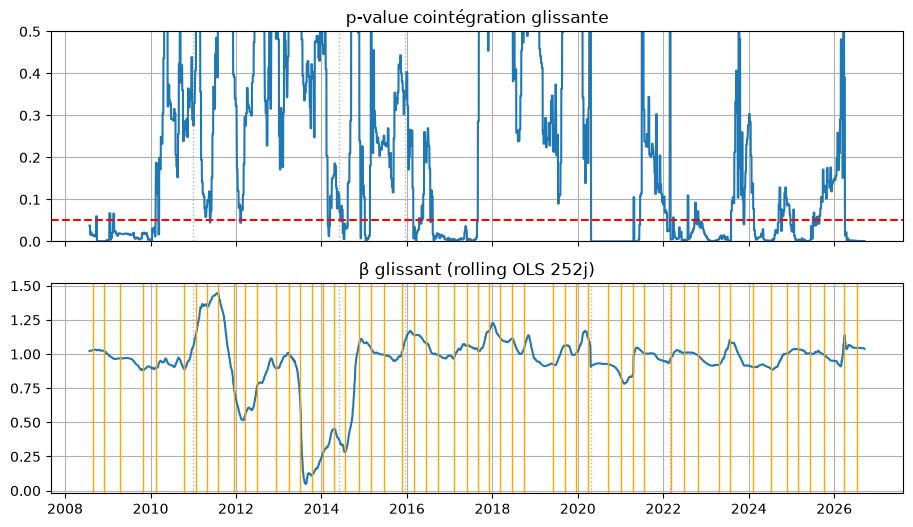

ruptures CUSUM sur β : ['2008-08-26', '2008-11-26', '2009-04-14', '2009-10-28', '2010-02-19', '2010-10-18', '2011-01-21', '2011-04-29', '2011-08-03', '2011-12-14', '2012-03-22', '2012-06-26', '2012-12-11', '2013-03-28', '2013-07-05', '2013-10-09', '2014-01-14', '2014-04-21', '2014-07-23', '2014-11-21', '2015-02-26', '2015-06-23', '2015-11-23', '2016-03-04', '2016-06-15', '2016-09-19', '2017-02-08', '2017-05-25', '2017-08-31', '2017-12-04', '2018-03-07', '2018-06-15', '2018-09-28', '2019-06-05', '2019-09-17', '2019-12-17', '2020-03-26', '2020-09-15', '2021-01-06', '2021-04-15', '2021-07-20', '2022-03-10', '2022-06-30', '2022-10-28', '2023-04-19', '2023-07-25', '2024-02-07', '2024-07-11', '2024-11-19', '2025-02-25', '2025-06-06', '2025-10-01', '2026-03-23', '2026-07-15']


In [4]:
ri = rg.regime_indicators(prices)
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax[0].plot(ri.index, ri['coint_pvalue']); ax[0].axhline(0.05, color='r', ls='--')
ax[0].set_title('p-value cointégration glissante'); ax[0].set_ylim(0,.5); events(ax[0])
ax[1].plot(ri.index, ri['rolling_beta']); ax[1].set_title('β glissant (rolling OLS 252j)'); events(ax[1])
for d in rg.cusum_breaks(ri['rolling_beta'].dropna(), threshold=8):
    ax[1].axvline(d, color='orange', lw=1)
plt.show()
print('ruptures CUSUM sur β :', [str(d.date()) for d in rg.cusum_breaks(ri['rolling_beta'].dropna(), threshold=8)])

**Lecture** : sur 1983-2024 le WTI est un peu plus souvent en backwardation (52 %), mais 2004-2024 a été dominé par le contango (carry négatif). Le spread est plus large en contango ; la courbe ne prédit pas de rendements forward significativement différents (|t| < 2). La cointégration glissante et les ruptures de β matérialisent **où la relation se déforme** — là où la stratégie doit être prudente.

*Limites : cutoff EIA 2024-04-05, pas de courbe Brent gratuite.*